In [ ]:
import os
import re
from typing import Annotated, Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field

from youtube_transcript_api import YouTubeTranscriptApi
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from langchain_groq import ChatGroq

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.checkpoint.memory import MemorySaver

# Set your Groq API Key
os.environ["GROQ_API_KEY"] = ""

c:\Users\karan\Desktop\langgraph\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\karan\AppData\Local\Temp\ipykernel_16468\4066157948.py:10: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


In [2]:
# !pip install -q sentence-transformers langchain-huggingface

# from huggingface_hub import logging
# logging.set_verbosity_info()

# from langchain_huggingface import HuggingFaceEmbeddings

# embeddings = HuggingFaceEmbeddings(
#     model_name="BAAI/bge-base-en-v1.5",
#     model_kwargs={"device": "cpu"},
#     encode_kwargs={"normalize_embeddings": True}
# )

In [ ]:
from langchain_huggingface import HuggingFaceEmbeddings

embedding = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 5529.20it/s]


In [29]:
# ==========================================
# STEP 2: Splitter, Embeddings & Vector Store
# ==========================================
def build_vector_store(transcript_text: str):
    # 1. Split transcript into overlapping chunks
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=1000,
        chunk_overlap=200,
        separators=["\n\n", "\n", ". ", " ", ""]
    )
    chunks = splitter.split_text(transcript_text)
    docs = [Document(page_content=chunk, metadata={"chunk_id": i}) for i, chunk in enumerate(chunks)]

    # 2. Hugging Face Embedding Model (Sweet spot: 109M params, 768 dims)

    embedding = HuggingFaceEmbeddings(
        model_name="sentence-transformers/all-MiniLM-L6-v2"
    )
    # 3. Create FAISS Vector Store
    vector_store = FAISS.from_documents(docs, embedding)

    # 4. Create MMR Retriever for diverse context
    retriever = vector_store.as_retriever(
        search_type="mmr",
        search_kwargs={"k": 4, "fetch_k": 12, "lambda_mult": 0.7}
    )
    return vector_store, retriever

In [30]:
# ==========================================
# STEP 3: LLM & Prompt Setup
# ==========================================
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0.2
)

# Structured output schema for the Router Node
class RouteDecision(BaseModel):
    route: Literal["chat", "rag", "summarize"] = Field(
        description=(
            "Choose 'chat' for greetings, small talk, or general questions about our conversation. "
            "Choose 'rag' when the user asks a specific question about facts, details, or topics in the video. "
            "Choose 'summarize' when the user asks for a summary, TL;DR, overview, or key takeaways of the video."
        )
    )

router_llm = llm.with_structured_output(RouteDecision)

In [43]:
class GraphState(TypedDict):
    messages: Annotated[list, add_messages]  # Shared chat history
    transcript: str                          # Full video transcript
    route: str                               # Router decision
    md_instruction: str                      # Optional instruction from Human-in-the-loop (e.g., "add design")
    md_file: str

In [32]:

# --- NODE 1: Router Node ---
def router_node(state: GraphState):
    user_last_msg = state["messages"][-1].content

    system_prompt = (
        "You are an intelligent intent router for a YouTube Video Assistant.\n"
        "Analyze the user's latest input and decide which node should handle it:\n"
        "1. 'chat': Greetings, casual conversation, thanking the bot, or meta-questions about our chat.\n"
        "2. 'rag': Specific questions asking for details, explanations, timestamps, or facts from the video.\n"
        "3. 'summarize': Requests to summarize the video, list key takeaways, or give a high-level overview."
    )
    decision = router_llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=user_last_msg)
    ])
    print(f"🧭 [Router Decision]: Routing to -> {decision.route.upper()}")
    return {"route": decision.route}

In [33]:
# --- NODE 2: Normal Chat Node (With Conversation Context + Video Awareness) ---
def chat_node(state: GraphState):
    # Give the chat node a brief peek at the beginning of the transcript so it knows what video is loaded
    video_preview = state["transcript"][:800]

    chat_prompt = ChatPromptTemplate.from_messages([
      ("system", 
        "You are a friendly, sharp YouTube AI assistant. Handle greetings, casual chat, and follow-up "
        "conversation naturally. You have access to our full conversation history below.\n"
        "For context, here is a preview of the loaded video transcript so you know the general topic:\n"
        "{video_preview}..."),
      MessagesPlaceholder(variable_name="messages")
    ])

    chain = chat_prompt | llm
    response = chain.invoke({
      "video_preview": video_preview,
      "messages": state["messages"]
    })
    return {"messages": [response]}


In [34]:

# --- NODE 3: RAG Node (Prompt + Retriever + Chat Context) ---
def rag_node(state: GraphState):
    user_question = state["messages"][-1].content
    
    # Retrieve relevant chunks from FAISS
    retrieved_docs = retriever.invoke(user_question)
    context_text = "\n\n---\n\n".join([doc.page_content for doc in retrieved_docs])
    
    rag_prompt = ChatPromptTemplate.from_messages([
        ("system",
          "You are an expert YouTube RAG assistant. Answer the user's question accurately using ONLY "
          "the provided transcript context and our conversation history. "
          "Whenever timestamps like [MM:SS] are present in the context, cite them in your answer! "
          "If the answer is not in the transcript, say so honestly.\n\n"
          "Retrieved Transcript Chunks:\n{context}"),
        MessagesPlaceholder(variable_name="messages")
    ])
    
    chain = rag_prompt | llm
    response = chain.invoke({
        "context": context_text,
        "messages": state["messages"]
    })
    return {"messages": [response]}

In [35]:

   
    # --- NODE 4: Summarizer Node ---
def summarizer_node(state: GraphState):
  # Important: Standard RAG only pulls 4 chunks, which is terrible for full-video summaries!
  # Here we feed the transcript (up to ~25,000 chars to stay well within Groq's token limits).
  transcript_for_summary = state["transcript"][:25000]
  
  summary_prompt = ChatPromptTemplate.from_messages([
      ("system",
        "You are an expert video summarizer. Based on the video transcript below, fulfill the user's "
        "summary request. Structure your response with:\n"
        "1. **Core Theme** (1-2 sentences)\n"
        "2. **Key Takeaways & Timestamps** (Bullet points)\n"
        "3. **Conclusion / Actionable Insight**\n\n"
        "Video Transcript:\n{transcript}"),
      MessagesPlaceholder(variable_name="messages")
  ])
  
  chain = summary_prompt | llm
  response = chain.invoke({
      "transcript": transcript_for_summary,
      "messages": state["messages"]
  })
  return {"messages": [response]}


In [36]:

# --- Conditional Edge Function ---
def select_next_node(state: GraphState) -> Literal["chat_node", "rag_node", "summarizer_node"]:
    if state["route"] == "chat":
        return "chat_node"
    elif state["route"] == "summarize":
        return "summarizer_node"
    else:
        return "rag_node"


In [44]:
# --- NODE 5: Smart & Adaptive Markdown Generator Node ---
def md_export_node(state: GraphState):
    filename = "youtube_notes.md"
    last_ai_response = state["messages"][-1].content
    user_last_question = state["messages"][-2].content if len(state["messages"]) >= 2 else ""
    human_instruction = state.get("md_instruction", "auto")

    md_prompt = ChatPromptTemplate.from_messages([
        ("system",
         "You are an expert technical writer creating a clean `.md` study note from the AI's latest response.\n\n"
         "### SMART DESIGN RULES (FOLLOW STRICTLY):\n"
         "1. **DO NOT force ASCII diagrams/trees on every note!** If the topic is a simple answer, definition, "
         "or normal summary, write clean, natural Markdown using `# Headings`, `> Callout quotes`, bullet points, "
         "and **bold** key terms.\n"
         "2. **WHEN TO INCLUDE A DESIGN:** Include a visual ASCII diagram ONLY IF:\n"
         "   - The user explicitly asked for a design/diagram/tree in their prompt or instruction (`{human_instruction}`), OR\n"
         "   - The topic genuinely needs structural visualization (e.g., system architecture, multi-layer breakdown, "
         "step-by-step workflow, or hierarchy).\n"
         "3. **HOW TO MAKE THE DESIGN (When Needed):**\n"
         "   - For hierarchies/topics: Use a clean folder tree (`📦`, `📂`, `├──`, `│`, `└──`) inside a ```text block.\n"
         "   - For processes/pipelines: Use a clean flow diagram (`[Step 1] ──► [Step 2] ──► [Result]`) inside a ```text block.\n"
         "   - For comparisons/timestamps: Use a clean Markdown table.\n\n"
         "Keep the formatting classy, readable, and well-spaced."),
        ("human",
         "User's Question: {question}\n\n"
         "AI's Answer to Convert into Markdown:\n{latest_answer}\n\n"
         "Human-in-the-Loop Extra Instruction: {human_instruction}")
    ])

    md_content = (md_prompt | llm).invoke({
        "question": user_last_question,
        "latest_answer": last_ai_response,
        "human_instruction": human_instruction
    }).content

    with open(filename, "w", encoding="utf-8") as f:
        f.write(md_content)

    print(f"✅ [MD Node]: '{filename}' successfully generated!")
    return {"md_file": filename}

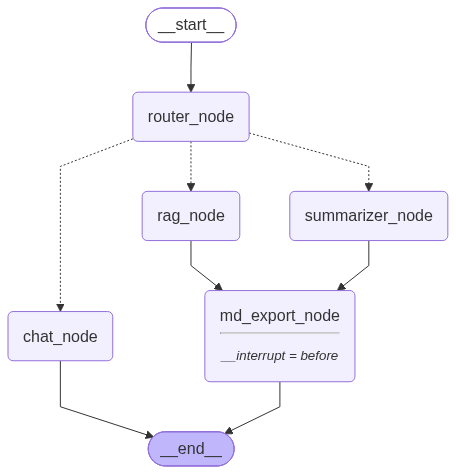

In [45]:
# --- Build the StateGraph ---
builder = StateGraph(GraphState)

builder.add_node("router_node", router_node)
builder.add_node("chat_node", chat_node)
builder.add_node("rag_node", rag_node)
builder.add_node("summarizer_node", summarizer_node)
builder.add_node("md_export_node", md_export_node)

builder.add_edge(START, "router_node")
builder.add_conditional_edges(
    "router_node",
    select_next_node,
    {
        "chat_node": "chat_node",
        "rag_node": "rag_node",
        "summarizer_node": "summarizer_node"
    }
)

# Normal chat goes straight to END (no need to ask for .md on "Hi/Hello")
builder.add_edge("chat_node", END)

# RAG and Summarizer go to md_export_node (which pauses for Human-in-the-Loop approval!)
builder.add_edge("rag_node", "md_export_node")
builder.add_edge("summarizer_node", "md_export_node")
builder.add_edge("md_export_node", END)

# Compile with MemorySaver AND Human-in-the-Loop interrupt!
memory = MemorySaver()
app = builder.compile(
    checkpointer=memory,
    interrupt_before=["md_export_node"]  # <-- PAUSES HERE UNTIL USER APPROVES!
)
app

In [46]:
config = {"configurable": {"thread_id": "hackathon_demo_1"}}

def ask_app(user_input: str):
    # Step 1: Run graph (It will answer and pause BEFORE md_export_node)
    result = app.invoke(
        {
            "messages": [HumanMessage(content=user_input)],
            "transcript": transcript_text
        },
        config=config
    )
    print(f"\n🤖 AI:\n{result['messages'][-1].content}\n" + "-" * 60)

    # Step 2: Check if the graph paused at the Human-in-the-Loop checkpoint
    state_snapshot = app.get_state(config)
    if "md_export_node" in state_snapshot.next:
        choice = input(
            "⏸️ [Human-in-the-Loop] Kya iska .md file banana hai? "
            "(Type 'n' to skip, 'y' for auto-format, or e.g. 'y ache se tree design banao'): "
        ).strip()

        if choice.lower() not in ["", "n", "no"]:
            # Pass user's design preference into state and resume the graph!
            app.update_state(config, {"md_instruction": choice})
            app.invoke(None, config=config)  # None resumes from the paused checkpoint
        else:
            print("⏭️ Skipped .md file generation.")

In [38]:
import re
from youtube_transcript_api import (
    YouTubeTranscriptApi, TranscriptsDisabled, NoTranscriptFound
)

def get_video_id(url_or_id: str) -> str:
    if re.fullmatch(r"[A-Za-z0-9_-]{11}", url_or_id):
        return url_or_id
    m = re.search(r"(?:v=|youtu\.be/|embed/|shorts/)([A-Za-z0-9_-]{11})", url_or_id)
    if not m:
        raise ValueError("Not a valid YouTube URL or video ID")
    return m.group(1)

def get_transcript_text(url_or_id, preferred_langs=("en", "hi"), return_language=False):
    video_id = get_video_id(url_or_id)
    try:
        transcript_list = YouTubeTranscriptApi().list(video_id)
        try:
            # prefers manual captions, then auto-generated, in your preferred languages
            transcript = transcript_list.find_transcript(list(preferred_langs))
        except NoTranscriptFound:
            # fall back to ANY language: manual first, then auto-generated
            available = sorted(transcript_list, key=lambda t: t.is_generated)
            if not available:
                raise ValueError("No transcripts available for this video")
            transcript = available[0]

        fetched = transcript.fetch()
        text = " ".join(s.text for s in fetched).replace("\n", " ")
        return (text, transcript.language_code) if return_language else text

    except TranscriptsDisabled:
        raise ValueError("Captions are disabled for this video")

In [47]:
video_url = "https://youtu.be/XRzFDTqhXOQ"

# Run the pipeline functions
transcript_text = get_transcript_text(video_url)
# docs = get_chunks(transcript_text)
# vector_store, retriever = create_vector_store_and_retriever(docs)
transcript_text

'these guys. If you want to clear job interviews, you need to master programming. I specifically curated this list of elsack projects because they are all fun, unique, and entertaining to build. Two, teaches new aspects of computer science and three makes recruiters come heavily. The projects will get progressively harder and more impressive. So, make sure you don\'t miss out on the best ones. But first, one of the best areas for beginner projects is the Gen AI playground because these projects are memorable, sharable, and low-key rum worthy even as a beginner project. Like a website that absolutely cooks you based on your YouTube watch history. First, the user logs in using Google O classic trap. Then use the YouTube\'s API to fetch their freshly liked videos, subscriptions, and playlist and parcel them into a hot Gemini API. Finally, s your users a roast report, a brain rot score, their red flag, and a brutally honest description about their personality that gives them existential re

In [48]:
vector_store, retriever = build_vector_store(transcript_text)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4382.36it/s]


In [49]:
retriever.invoke("what is the video about?")

[Document(id='6ee88a37-e99b-4cef-8bc9-6aa25e30fb3e', metadata={'chunk_id': 1}, page_content=". Finally, s your users a roast report, a brain rot score, their red flag, and a brutally honest description about their personality that gives them existential red. Yes, make them cry. You can also do that by building a Spotify roast app by fetching users most listened songs and artists. But instead, if you want to use AI for humanity's benefit, uh well, you cannot do that. But something close would be an AI that creates videos to explain any topic you ask. Yes, this looks very fancy and complicated, but under the hood, you're just calling another LLM API to generate a video using Remotion, which is a JavaScript library to create animations using code. But the problem here is that the boilerplate code for a Remotion project is humongous. So instead, we'll only ask LLM to generate code for this file and hardcode the rest of the boiler plate in the server itself"),
 Document(id='fb158a3e-5518-4f

In [50]:
# Shared session thread ID so memory persists across every call
config = {"configurable": {"thread_id": "user_session_1"}}

def ask_app(user_input: str):
    result = app.invoke(
        {
            "messages": [HumanMessage(content=user_input)],
            "transcript": transcript_text
        },
        config=config
    )
    print(f"🤖 AI:\n{result['messages'][-1].content}\n" + "=" * 60)


# 1. Test Chat Node (saves your name in shared memory)
ask_app("Hi! I am kapil. What is this video about in one line?")

# 2. Test RAG Node (retrieves exact chunks from FAISS)
ask_app("Why does the video say the first layer has 784 neurons?")

# 3. Test Summarizer Node (uses full transcript + remembers your name from Turn 1!)
ask_app("Give me a structured summary of this video and mention my name at the start.")

🧭 [Router Decision]: Routing to -> SUMMARIZE
🤖 AI:
A fast‑paced guide showcasing standout coding project ideas—AI‑driven apps, data‑visualization tools, creative visualizers, and multiplayer games—to supercharge your portfolio and ace tech interviews.
🧭 [Router Decision]: Routing to -> RAG
🤖 AI:
The transcript you provided doesn’t contain any mention of a “first layer” with 784 neurons, so I can’t answer that question from the available content.
🧭 [Router Decision]: Routing to -> SUMMARIZE
🤖 AI:
**Kapil – Structured Summary**

---

### 1. Core Theme  
A rapid‑fire showcase of fun, impressive, and interview‑friendly coding projects—ranging from Gen AI playgrounds and data‑driven visualizers to multiplayer games and AI‑agent pipelines—that teach new CS concepts while making your résumé stand out.

---

### 2. Key Takeaways & Approximate Timestamps  

| Timestamp (approx.) | Takeaway |
|---------------------|----------|
| **0:00 – 0:45** | **Why project work matters** – Mastering programm

In [51]:
ask_app("Give me a structured summary of this video and mention my name at the start.")

🧭 [Router Decision]: Routing to -> SUMMARIZE
🤖 AI:
**Kapil – Structured Summary**

---

### 1. Core Theme  
A rapid‑fire tour of eye‑catching, interview‑ready coding projects—AI‑driven apps, data‑visualization dashboards, 3‑D visualizers, and multiplayer games—that teach new CS concepts while making your portfolio stand out.

---

### 2. Key Takeaways & Approximate Timestamps  

| Time (≈) | Highlight |
|----------|-----------|
| **0:00‑0:45** | **Why projects matter** – Building fun, unique apps is the fastest way to clear coding interviews and attract recruiters. |
| **0:46‑2:10** | **Gen AI Playground** – Ideas like a “YouTube Roast” (Google login → YouTube API → Gemini → brutal personality report) and a Spotify‑roast variant. |
| **2:11‑3:30** | **AI‑generated video explainer** – Call an LLM to produce Remotion code, run it server‑side, return an MP4 video. |
| **3:31‑4:20** | **Video‑to‑notes generator** – Pull a YouTube transcript, feed it to an LLM with a crafted prompt, deliver

In [52]:
ask_app("Give me a structured summary of this video and mention my name at the start.")

🧭 [Router Decision]: Routing to -> SUMMARIZE
🤖 AI:
**Kapil – Structured Summary**

---

### 1. Core Theme  
A fast‑paced showcase of eye‑catching, interview‑ready coding projects—AI‑driven apps, data‑visualization dashboards, 3‑D visualizers, and multiplayer games—that teach new computer‑science concepts while making your portfolio stand out.

---

### 2. Key Takeaways & Approximate Timestamps  

| Approx. Time | Takeaway |
|--------------|----------|
| **0:00 – 0:45** | **Why projects matter** – Building fun, unique apps is the quickest way to clear coding interviews and attract recruiters. |
| **0:46 – 2:10** | **Gen AI Playground** – Ideas like a “YouTube Roast” (Google login → YouTube API → Gemini → brutally honest personality report) and a Spotify‑roast variant. |
| **2:11 – 3:30** | **AI‑generated video explainer** – Use an LLM to emit Remotion (JS animation) code, run it server‑side, and serve the MP4 video to users. |
| **3:31 – 4:20** | **Video‑to‑notes generator** – Pull a Yo